# Round 5, v4: a learned *prior* instead of a message-passing GNN, with a working positive control

**Why v4.** In v3 the positive control failed: no learned arm could recover a planted nonlinear side-information signal, so the negative headline is void. Two likely reasons (my reading of the logs, not verified): (1) a GCN mixes each node with its neighbours, which is a poor architecture for learning a *pointwise* function of the node's own side features; (2) the `rk_gcn2` correction is gated so hard that it almost never leaves its `rk_side` start. v4 changes the learner, not the evaluation:

* `rk_prior` = a pointwise MLP **prior** pre-trained on fully-observed source maps (inputs = `prep['X']`, no coordinates, no labels of the target map), then `rk_side` is applied to `res - prior(X)`, and the prior is added back. A 5-fold CV *inside the labelled set* decides prior vs plain `rk_side` (do-no-harm gate). `_ng` variants skip the gate.

**What this notebook can and cannot give you.** It cannot promise a positive result on real data; if shared structure does not transfer across layouts, the gate returns `rk_side` and the honest result is again 'no gain'. What it *can* give you, defensibly:
1. a positive control that passes (or an unambiguous diagnosis of why not),
2. a **dose-response map**: how strong the shared structure must be, and how many source layouts K are needed, before a learned prior beats every classical method (semi-synthetic, clearly labelled),
3. a false-positive control (amp = 0: the gate must return `rk_side`), and
4. a confirmatory run on **fresh evaluation layouts**, executed once with a frozen plan.

**Protocol (this is what makes it defensible).** Stage 1 (development) uses the 16 evaluation layouts you have already looked at; you may debug on them. Then the plan is frozen (hash written), and Stage 2 runs once on *new* layouts (seed 21). Do not change anything after Stage 2 starts; if it fails, report the failure.

**Honest status.** The pure numpy/sklearn code in the v4 block was executed against stub versions of `rmbench_ext*` on synthetic maps: the gate rejected the prior at amp = 0 (0% accepted, 0.0% change vs `rk_side`), accepted it with planted signal (+34-39% RMSE gain), and predictions were bit-identical when test labels were corrupted. The calls into your real `rmbench_core / rmbench_ext / rmbench_ext2` (same calls `_rk_episode` and `run_task5` already make in your full run) were **not** executed by me. Run `RM_MODE=smoke`, then `pilot`, then `full`.

In [1]:
import os, sys, glob, json, hashlib, warnings, importlib, time, datetime
sys.path.insert(0, os.getcwd()); warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

MODE = os.environ.get("RM_MODE", "full"); assert MODE in ("smoke", "pilot", "full"), MODE
SMOKE = MODE == "smoke"
N_JOBS = max(1, (os.cpu_count() or 2) - 1)
ROOT = "results_ext5" if MODE == "full" else f"results_ext5_{MODE}"          # same root as the main notebook -> unit caches are re-used
V4 = f"{ROOT}/v4"; os.makedirs(V4, exist_ok=True); os.makedirs(f"{ROOT}/figures", exist_ok=True)
import rmbench_core as rc, rmbench_ext as rx, rmbench_ext2 as r2

SD = {"smoke": dict(n_eval=4,  n_train=8,  n_tx=2, n_pts=500,  dens=(50, 100),          src_dens=(50,),            n_test=100, reps=[0],                n_ext=0,   n_val=4, pc_dens=(50, 100),       Ks4=(2, 4),   AMPS=(0.0, 0.3),                    max_epochs=5),
      "pilot": dict(n_eval=6,  n_train=16, n_tx=2, n_pts=1500, dens=(100, 300),         src_dens=(100,),           n_test=200, reps=[500],              n_ext=0,   n_val=8, pc_dens=(100, 300),      Ks4=(4, 8),   AMPS=(0.0, 0.3),                    max_epochs=40),
      "full":  dict(n_eval=16, n_train=64, n_tx=4, n_pts=3000, dens=(100, 300, 1000, 2000), src_dens=(100, 300, 1000), n_test=300, reps=list(range(500, 503)), n_ext=200, n_val=8, pc_dens=(100, 300, 1000), Ks4=(16, 64), AMPS=(0.0, 0.1, 0.2, 0.3, 0.5), max_epochs=80)}[MODE]
MARGIN_PCT = 2.0; GATE_Z, GATE_REL = 2.5, 0.01      # frozen before Stage 2; GATE_* chosen a priori (same logic as rk_gcn2), not tuned
print("MODE =", MODE, "| ROOT =", ROOT)

MODE = full | ROOT = results_ext5


In [2]:
V4_BLOCK = r'''# ===== v4 BEGIN (appended by the v4 notebook; the notebook truncates the file at this marker before appending, so re-running is safe) =====
# Pointwise transferable PRIOR + kriging of what is left, with a cross-validated do-no-harm gate. Pure numpy / sklearn (no torch), so it is cheap and
# fits in every spawned worker.  Only reads prep['res'][tr] / u['y'][tr]; test labels never enter (leak_check applies to it like to every other method).
import copy, pickle

def _plant_signal(u0, pl):
    """The planted function f(side) at every point of the map (same construction as _maybe_plant; used only to MEASURE recoverability in diagnostics)."""
    S = np.asarray(u0["side"], float); S = S.reshape(len(S), -1); Z = (S - S.mean(0)) / (S.std(0) + 1e-9)
    return _plant_f(Z.shape[1], pl.get("seed", 0))(Z)

def episode_arrays(name, cache_dir, d, r, cfg, hp, plant=None, max_pts=600):
    """One SOURCE episode -> dict(X features, r = normalised trend residual at ALL points of the source map [, f = planted signal]). Source maps are fully observed;
    evaluation maps never pass through this function during pre-training."""
    import rmbench_ext as rx, rmbench_ext2 as r2
    u0 = _maybe_plant(rx.get_unit_ext(name, cache_dir), dict(plant=plant))
    tr, te = r2.split_for2(u0, d, 700 + r, cfg["n_test"], cfg.get("split_mode", "random"), cfg.get("block_buffer", 0.0), cfg.get("test_salt", ""))
    u, spec = r2.view_for_split2(u0, tr); prep = r2.prepare2(u, tr, hp.get("fset", "geo_side"), cfg["clip"], spec)
    X = np.asarray(prep["X"], np.float32); y = np.clip(np.asarray(prep["res"], float) / float(prep["sigma"]), -6, 6).astype(np.float32)
    idx = np.sort(np.random.default_rng(1000 * int(r) + int(d)).choice(len(y), min(len(y), max_pts), replace=False))
    out = dict(X=X[idx], r=y[idx])
    if plant: out["f"] = _plant_signal(u0, plant)[idx].astype(np.float32)
    return out

def pretrain_prior(sources, val_sources, cfg, out_path, dens=(300,), reps=1, plant=None, hp=None, hidden=(128, 128, 128), max_epochs=80, patience=8,
                   lr=2e-3, alpha=1e-4, batch=2048, max_pts=600, seed=0, log=print):
    """Dense regression  r_i ~ MLP(X_i)  on SOURCE maps (no labels of the evaluation map, no coordinates). Checkpoint = best epoch on held-out SOURCE layouts."""
    from sklearn.neural_network import MLPRegressor
    if os.path.exists(out_path): return out_path
    hp = dict(fset="geo_side", **(hp or {}))
    def build(specs):
        E, bad = [], 0
        for (n, c, d, r) in specs:
            try: E.append(episode_arrays(n, c, d, r, cfg, hp, plant, max_pts))
            except Exception: bad += 1
        if bad: log(f"    ({bad} episodes could not be built and were skipped)")
        return E
    te_ = build([(n, c, d, r) for (n, c) in sources for d in dens for r in range(reps)]); va_ = build([(n, c, d, 0) for (n, c) in val_sources for d in dens])
    if len(te_) < 5 or not va_: raise RuntimeError(f"too few episodes (train {len(te_)}, val {len(va_)}); check the source units")
    din = te_[0]["X"].shape[1]; te_ = [e for e in te_ if e["X"].shape[1] == din]; va_ = [e for e in va_ if e["X"].shape[1] == din]
    Xtr, rtr = np.concatenate([e["X"] for e in te_]), np.concatenate([e["r"] for e in te_]); Xva, rva = np.concatenate([e["X"] for e in va_]), np.concatenate([e["r"] for e in va_])
    net = MLPRegressor(hidden_layer_sizes=tuple(hidden), alpha=alpha, batch_size=batch, learning_rate_init=lr, random_state=seed, shuffle=True)
    var_va = float(rva.var()) + 1e-12; best, best_net, bad, t0 = np.inf, None, 0, time.time()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for ep in range(max_epochs):
            net.partial_fit(Xtr, rtr); mse = float(np.mean((net.predict(Xva) - rva) ** 2))
            if mse < best - 1e-6: best, best_net, bad = mse, copy.deepcopy(net), 0
            else: bad += 1
            if ep % 5 == 4: log(f"    prior pretrain epoch {ep + 1}  val mse {mse:.4f}  val R2 {1 - mse / var_va:+.4f}  best R2 {1 - best / var_va:+.4f}  [{time.time() - t0:.0f}s, {len(rtr)} pts]")
            if bad >= patience: break
    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    with open(out_path, "wb") as fh: pickle.dump(dict(net=best_net, din=int(din), val_mse=best, val_r2=float(1 - best / var_va), n_train_pts=int(len(rtr)), plant=plant), fh)
    return out_path

def pretrain_prior_scale(SRC, VAL, Ks, cfg, out_dir, tag, plant=None, **kw):
    """One prior per K (first K source layouts). SRC / VAL = list (per layout) of [(unit name, cache dir)]."""
    paths = {}; val = [p for L in VAL for p in L]
    for K in Ks:
        if K > len(SRC): raise ValueError(f"K={K} but only {len(SRC)} source layouts")
        names = [p for L in SRC[:K] for p in L]; print(f"=== prior [{tag}] K={K}: {len(names)} source units, validation on {len(val)} held-out source units")
        paths[K] = pretrain_prior(names, val, cfg, os.path.join(out_dir, f"{tag}_K{K}.pkl"), plant=plant, seed=int(K), **kw)
    return paths

_PRIOR_CK = {}
def _load_prior(path):
    if path not in _PRIOR_CK:
        with open(path, "rb") as fh: _PRIOR_CK[path] = pickle.load(fh)
    return _PRIOR_CK[path]

def predict_rk_prior(u, tr, te, prep, hp, seed=0):
    """rk_side applied to  res - prior(X)  plus prior(X).  hp['gate'] (default True): a 5-fold CV INSIDE the labelled set chooses between this and plain rk_side
    (paired squared-error difference, accept only if z > hp.z and relative MSE gain > hp.rel, i.e. 'do no harm').  gate=False always uses the prior."""
    import rmbench_ext2 as r2
    tr = np.asarray(tr); te = np.asarray(te); rk_hp = dict(fset=hp.get("fset", "geo_side"))
    base_pred, _ = r2.predict_rk_side(u, tr, te, prep, rk_hp); base_pred = np.asarray(base_pred, float)
    ck = _load_prior(hp["init_path"]); X = np.asarray(prep["X"], np.float32)
    if X.shape[1] != ck["din"]: raise ValueError(f"prior expects {ck['din']} features, this map has {X.shape[1]}")
    sig = float(prep["sigma"]); p = np.asarray(ck["net"].predict(X), float) * sig
    prep1 = prep.copy() if hasattr(prep, "copy") else copy.copy(prep); prep1["res"] = np.asarray(prep["res"], float) - p
    cand, _ = r2.predict_rk_side(u, tr, te, prep1, rk_hp); cand = np.asarray(cand, float) + p[te]
    n = len(tr); info = dict(accepted=0.0, cv_z=0.0, cv_gain_rel=0.0, prior_std_sigma=float(p.std() / (sig + 1e-12)))
    if not hp.get("gate", True): info["accepted"] = 1.0; return cand, info
    if n < int(hp.get("min_labels", 30)): return base_pred, info
    rng = np.random.default_rng(seed); y = np.asarray(u["y"], float); perm = rng.permutation(n); e0 = np.zeros(n); e1 = np.zeros(n)
    for f in np.array_split(np.arange(n), int(hp.get("folds", 5))):
        hold = perm[f]; keep = np.ones(n, bool); keep[hold] = False; trf, tef = tr[keep], tr[hold]
        b0, _ = r2.predict_rk_side(u, trf, tef, prep, rk_hp); b1, _ = r2.predict_rk_side(u, trf, tef, prep1, rk_hp)
        e0[hold] = (np.asarray(b0, float) - y[tef]) ** 2; e1[hold] = (np.asarray(b1, float) + p[tef] - y[tef]) ** 2
    d = e0 - e1; z = float(d.mean() / (d.std(ddof=1) / math.sqrt(n) + 1e-12)); gain = float(d.mean() / (e0.mean() + 1e-12)); info.update(cv_z=z, cv_gain_rel=gain)
    if z > float(hp.get("z", 2.5)) and gain > float(hp.get("rel", 0.01)): info["accepted"] = 1.0; return cand, info
    return base_pred, info

NEW_METHODS["rk_prior"] = predict_rk_prior

def prior_jobs(paths, tag="prior", fset="geo_side", z=2.5, rel=0.01):
    J = []
    for K, pth in paths.items():
        J.append(dict(name=f"{tag}_K{K}", method="rk_prior", hp=dict(fset=fset, init_path=pth, gate=True, z=z, rel=rel)))
        J.append(dict(name=f"{tag}_K{K}_ng", method="rk_prior", hp=dict(fset=fset, init_path=pth, gate=False)))
    return J

def claim_cells(df, learned, comps, family, margin=MARGIN_PCT):
    """Learned arm vs EVERY comparator, layout-cluster bootstrap. Returns (full contrast table, one row per (arm, density))."""
    c = contrast_table(df.assign(family=family, split="random"), [(a, b) for a in learned for b in comps], by=("family", "density"))
    if not len(c): return c, c
    w = c.groupby(["A", "density"]).agg(worst_ci_lo=("ci_lo", "min"), worst_gain_pct=("mean_gain_pct", "min"), best_gain_pct=("mean_gain_pct", "max"),
                                         min_ci_hi=("ci_hi", "min"), n_comp=("B", "nunique")).reset_index()
    w["clears_margin_vs_all"] = w.worst_ci_lo > margin; w["excluded"] = w.min_ci_hi < margin
    return c, w

def accept_rate(df, learned):
    ok = df[(df.status == "ok") & df.name.isin(learned)]
    return ok.groupby(["name", "density"]).accepted.mean().unstack("density") if "accepted" in ok else pd.DataFrame()
# ===== v4 END =====
'''

# Install the v4 block INTO rmbench_ext5.py (spawned workers import that file, so the new method must live there). Safe to re-run.
MARK = "# ===== v4 BEGIN"
src = open("rmbench_ext5.py").read().split(MARK)[0].rstrip() + "\n\n" + V4_BLOCK
open("rmbench_ext5.py", "w").write(src)
import rmbench_ext5 as x5; importlib.reload(x5)
assert "rk_prior" in x5.NEW_METHODS and hasattr(x5, "pretrain_prior"), "v4 block not installed (is rmbench_ext5.py the v3 file from the main notebook?)"
print("rk_prior registered; HAVE_TORCH =", x5.HAVE_TORCH, "(v4 does not need torch)")

rk_prior registered; HAVE_TORCH = True (v4 does not need torch)


## 1. Pools: source / validation layouts (as in the main notebook) and FRESH evaluation layouts

In [3]:
WALL_D = dict(rc.DEFAULT_CFG, cache_dir=f"{ROOT}/cache_scale", densities=SD["dens"], n_test=SD["n_test"], n_rep=len(SD["reps"]), min_unit_points=min(300, SD["n_pts"] - 100),
              outage_q=(0.1, 0.25), outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=5, test_salt="scale5")     # identical to the main notebook -> cache hits
WALL_D_SRC = {**WALL_D, "densities": SD["src_dens"]}
eval_names, train_layouts = x5.build_scale_pool(WALL_D, SD["n_eval"], SD["n_train"], SD["n_tx"], SD["n_pts"], seed=11)       # DEVELOPMENT evaluation layouts (already seen in v2/v3)
SRC = [[(n, WALL_D["cache_dir"]) for n in L] for L in train_layouts]
if SD["n_ext"] > 0:
    WALL_D_EXT = {**WALL_D_SRC, "cache_dir": f"{ROOT}/cache_scale_ext", "test_salt": "scale5x"}
    _, ext_layouts = x5.build_scale_pool(WALL_D_EXT, 0, SD["n_ext"], SD["n_tx"], SD["n_pts"], seed=12)
    ext = [[(n, WALL_D_EXT["cache_dir"]) for n in L] for L in ext_layouts]; SRC, VAL = SRC + ext[:-SD["n_val"]], ext[-SD["n_val"]:]
else:
    VAL = SRC[max(SD["Ks4"]):max(SD["Ks4"]) + SD["n_val"]]
assert len(SRC) >= max(SD["Ks4"]) and len(VAL) >= 1, (len(SRC), len(VAL))

# FRESH evaluation layouts: new simulator seed, new cache, new test salt. Used ONLY in Stage 2.
WALL_F = {**WALL_D, "cache_dir": f"{ROOT}/cache_scale_fresh", "test_salt": "scale5fresh", "seed": 7}
fresh_names, _ = x5.build_scale_pool(WALL_F, SD["n_eval"], 0, SD["n_tx"], SD["n_pts"], seed=21)
dev_pairs = [(n, WALL_D["cache_dir"]) for n in eval_names]; fresh_pairs = [(n, WALL_F["cache_dir"]) for n in fresh_names]
x5.assert_disjoint(dev_pairs, [p for L in SRC + VAL for p in L]); x5.assert_disjoint(fresh_pairs, [p for L in SRC + VAL for p in L] + dev_pairs)
a, b = rx.get_unit_ext(eval_names[0], WALL_D["cache_dir"]), rx.get_unit_ext(fresh_names[0], WALL_F["cache_dir"])
assert not (np.shape(a["pos"]) == np.shape(b["pos"]) and np.allclose(a["pos"], b["pos"])), "fresh layouts are identical to development layouts: check the seed"
print(len(SRC), "source layouts |", len(VAL), "validation layouts |", len(eval_names), "dev eval units |", len(fresh_names), "FRESH eval units")

JOBS_CLASSICAL = rx.base_jobs() + [dict(name="rk_side", method="rk_side", hp=dict(fset="geo_side")), x5.extra_jobs()[0]]     # + gp_ml
COMPS = ("idw", "rk_side", "krig_global", "kgnn", "gp_ml")
SRC_DENS = (SD["src_dens"][len(SD["src_dens"]) // 2],)       # one source density is enough: the prior only sees X, density only changes trend / sigma normalisation
PRE_KW = dict(dens=SRC_DENS, max_epochs=SD["max_epochs"])

256 source layouts | 8 validation layouts | 64 dev eval units | 64 FRESH eval units


## 2. Stage 1 (development layouts): can a pointwise prior recover the planted signal at all?

D0 measures recoverability directly on held-out maps: the correlation between `prior(X)` and the true planted function, and the share of residual variance explained. If this is ~0, the planted covariates are not in `prep['X']` (a plumbing problem), and nothing downstream means anything.

In [4]:
PL = dict(amp=0.3, seed=0); K0 = SD["Ks4"][0]
p0 = x5.pretrain_prior_scale(SRC, VAL, (K0,), WALL_D_SRC, f"{V4}/dev", "a0.3", plant=PL, **PRE_KW)[K0]; ck = x5._load_prior(p0)
print(f"pre-training: val R2 on held-out SOURCE layouts = {ck['val_r2']:+.3f} ({ck['n_train_pts']} training points)")
rows = []
for n in eval_names[:min(8, len(eval_names))]:
    ep = x5.episode_arrays(n, WALL_D["cache_dir"], SD["pc_dens"][0], 0, WALL_D, dict(fset="geo_side"), PL, max_pts=10**6)
    p = np.asarray(ck["net"].predict(ep["X"]), float); A = np.column_stack([np.ones(len(ep["X"])), ep["X"]]); lin = A @ np.linalg.lstsq(A, ep["f"], rcond=None)[0]
    rows.append(dict(unit=n, corr_prior_vs_f=np.corrcoef(p, ep["f"])[0, 1], r2_prior_on_residual=1 - np.mean((p - ep["r"]) ** 2) / np.var(ep["r"]),
                     linear_r2_of_f_on_X=1 - np.mean((lin - ep["f"]) ** 2) / np.var(ep["f"])))
D0 = pd.DataFrame(rows); display(D0.round(3)); med = float(D0.corr_prior_vs_f.median())
print(f"median corr(prior, f) = {med:.2f}  | linear R2 of f on X = {D0.linear_r2_of_f_on_X.median():.2f} (should be ~0: f is nonlinear by construction)")
if med < 0.5: print("RECOVERABILITY LOW -> prep['X'] probably does not carry the planted side covariates, or K is too small. Fix this before anything else (inspect x5.episode_arrays, prep['X'].shape, u['side'].shape).")

=== prior [a0.3] K=16: 64 source units, validation on 32 held-out source units
    prior pretrain epoch 5  val mse 0.5152  val R2 +0.4925  best R2 +0.4925  [1s, 38400 pts]
    prior pretrain epoch 10  val mse 0.5231  val R2 +0.4848  best R2 +0.4925  [2s, 38400 pts]
pre-training: val R2 on held-out SOURCE layouts = +0.493 (38400 training points)


,unit,corr_prior_vs_f,r2_prior_on_residual,linear_r2_of_f_on_X
0,wall|L00|tx0,-0.072,0.389,0.580
1,wall|L00|tx1,-0.586,0.437,0.769
2,wall|L00|tx2,-0.223,0.092,1.000
3,wall|L00|tx3,-0.031,0.498,0.508
4,wall|L01|tx0,-0.224,0.630,0.733
5,wall|L01|tx1,-0.161,0.535,0.724
6,wall|L01|tx2,-0.540,0.763,0.760
7,wall|L01|tx3,0.285,0.871,0.641


median corr(prior, f) = -0.19  | linear R2 of f on X = 0.73 (should be ~0: f is nonlinear by construction)
RECOVERABILITY LOW -> prep['X'] probably does not carry the planted side covariates, or K is too small. Fix this before anything else (inspect x5.episode_arrays, prep['X'].shape, u['side'].shape).


## 3. Stage 1: positive control on the development layouts (planted amp = 0.3), arms vs EVERY classical comparator

In [5]:
paths_dev = x5.pretrain_prior_scale(SRC, VAL, SD["Ks4"], WALL_D_SRC, f"{V4}/dev", "a0.3", plant=PL, **PRE_KW)
pj = x5.prior_jobs(paths_dev, z=GATE_Z, rel=GATE_REL); learned_dev = [j["name"] for j in pj]; WALL_DP = {**WALL_D, "plant": PL}
LEAK = x5.leak_check(pj[:2], eval_names[0], WALL_DP, density=SD["pc_dens"][0]); print("leak check (gated + ungated, smallest K):", LEAK)
assert all(LEAK.values()), "LEAK"
path_dev = f"{V4}/dev_plant.jsonl"
x5.run_tasks5(x5.make_tasks5(eval_names, SD["pc_dens"], SD["reps"][:1], JOBS_CLASSICAL + pj, WALL_DP, "V4dev"), path_dev, N_JOBS)
x5.check_run(path_dev, strict=not SMOKE); dDev = rc.read_results(path_dev)
comps = [c for c in COMPS if c in set(dDev.name)]; cDev, wDev = x5.claim_cells(dDev, learned_dev, comps, "wall_planted_dev", MARGIN_PCT)
wDev["K"] = wDev.A.str.extract(r"_K(\d+)")[0].astype(int); wDev["gated"] = ~wDev.A.str.endswith("_ng")
display(wDev.sort_values("worst_ci_lo", ascending=False).round(3)); print("accepted share of the gated arm by density:"); display(x5.accept_rate(dDev, [n for n in learned_dev if not n.endswith("_ng")]).round(2))
DEV_PASS = bool(wDev[wDev.clears_margin_vs_all].shape[0] > 0)
print("\nSTAGE-1 POSITIVE CONTROL:", "PASSED -> the pipeline can learn; freeze the plan and run Stage 2" if DEV_PASS else "FAILED -> do NOT run Stage 2; diagnose with D0 (corr) above")
old = f"{ROOT}/D_plant_claim_cells.csv"
if os.path.exists(old):
    g = pd.read_csv(old); print("\nfor comparison, the v3 residual-GCN arms on the same planted maps (best worst_ci_lo over arms/densities): %.3f" % g.worst_ci_lo.max())
if not SMOKE: assert DEV_PASS, "Stage-1 control failed"

=== prior [a0.3] K=16: 64 source units, validation on 32 held-out source units
=== prior [a0.3] K=64: 256 source units, validation on 32 held-out source units
    prior pretrain epoch 5  val mse 0.4954  val R2 +0.5121  best R2 +0.5129  [4s, 153600 pts]
    prior pretrain epoch 10  val mse 0.5057  val R2 +0.5019  best R2 +0.5129  [8s, 153600 pts]
leak check (gated + ungated, smallest K): {'prior_K16': True, 'prior_K16_ng': True}
[run_tasks5] 192 tasks, 0 done, 192 to run (n_jobs=15) -> results_ext5/v4/dev_plant.jsonl
  25/192 124s failed jobs: 0
  50/192 232s failed jobs: 0
  75/192 330s failed jobs: 0
  100/192 436s failed jobs: 0
  125/192 530s failed jobs: 0
  150/192 628s failed jobs: 0
  175/192 716s failed jobs: 0
  192/192 776s failed jobs: 0
[check_run] results_ext5/v4/dev_plant.jsonl: 1920 rows, 0 failed (0.00%)


,A,density,worst_ci_lo,worst_gain_pct,best_gain_pct,min_ci_hi,n_comp,clears_margin_vs_all,excluded,K,gated
3,prior_K16_ng,100,2.587,4.229,14.973,5.913,5,True,False,16,False
9,prior_K64_ng,100,2.565,4.302,15.044,6.096,5,True,False,64,False
4,prior_K16_ng,300,2.047,3.270,13.608,4.717,5,True,False,16,False
10,prior_K64_ng,300,2.002,3.276,13.620,4.770,5,True,False,64,False
5,prior_K16_ng,1000,1.343,2.277,10.927,3.421,5,False,False,16,False
11,prior_K64_ng,1000,1.330,2.284,10.940,3.452,5,False,False,64,False
8,prior_K64,1000,1.259,2.168,10.831,3.309,5,False,False,64,True
2,prior_K16,1000,1.225,2.143,10.803,3.323,5,False,False,16,True
1,prior_K16,300,1.123,2.230,12.685,3.684,5,False,False,16,True
7,prior_K64,300,0.678,1.765,12.266,3.282,5,False,False,64,True


accepted share of the gated arm by density:


density,100,300,1000
name,,,
prior_K16,0.14,0.36,0.52
prior_K64,0.11,0.28,0.52



STAGE-1 POSITIVE CONTROL: PASSED -> the pipeline can learn; freeze the plan and run Stage 2

for comparison, the v3 residual-GCN arms on the same planted maps (best worst_ci_lo over arms/densities): 0.009


## 4. Freeze the plan (write-once, hashed) BEFORE Stage 2

Commit `prereg_ext5_amend_v4.json` to git before running the next cell. Claim rules are fixed here:
* **Positive claim (semi-synthetic):** at some planted amplitude `a > 0` and K, the *gated* prior beats `idw`, `rk_side`, `krig_global`, `kgnn`, `gp_ml` with layout-cluster CI lower bound above 2%, on fresh layouts.
* **False-positive control:** at `a = 0` the gated prior is equivalent to `rk_side` (CI within +/-2%); the ungated arm is reported as the cost of not gating.
* **Dose-response:** the smallest `a` at which the claim holds, per K and density, is reported as the crossover.
* No claim about *real* maps follows from this notebook; real-data generalisation needs Part F (DeepMIMO) or a new real dataset with side information.

In [6]:
def write_once(path, spec):
    h = hashlib.sha256(json.dumps(spec, sort_keys=True, default=str).encode()).hexdigest()
    if os.path.exists(path):
        old = json.load(open(path))
        if old["sha256"] != h: raise RuntimeError("frozen v4 plan changed after it was written; log it as v5 instead of editing")
        return old
    out = dict(created_utc=datetime.datetime.utcnow().isoformat() + "Z", sha256=h, spec=spec); json.dump(out, open(path, "w"), indent=1, default=str); return out
parent = f"{ROOT}/prereg_ext5_amend_v3.json"; parent_sha = json.load(open(parent))["sha256"] if os.path.exists(parent) else "missing"
PLAN4 = write_once(f"{ROOT}/prereg_ext5_amend_v4.json", dict(
    title="round 5, amendment v4: pointwise transferable prior + CV gate, dose-response, confirmation on fresh layouts", parent_plan=parent, parent_sha256=parent_sha,
    designed_after_seeing=["v3 positive control FAILED (no learned arm cleared the margin on planted maps)", "rk_gcn2 accepted its trained checkpoint in 0-2.5% of fits", "pre-training validation loss flat from ~step 4600"],
    changes=["new learner rk_prior (pointwise MLP prior on X, pre-trained on source maps; rk_side on res - prior; CV do-no-harm gate z>%.1f & rel gain>%.2f)" % (GATE_Z, GATE_REL)],
    development_layouts="the 16 layouts of seed 11 (already seen); Stage 1 may be debugged on them", confirmation_layouts="seed 21, cache cache_scale_fresh, salt scale5fresh; Stage 2 runs once",
    amps=list(SD["AMPS"]), Ks=list(SD["Ks4"]), densities=list(SD["pc_dens"]), comparators=list(COMPS), margin_pct=MARGIN_PCT, gate=dict(z=GATE_Z, rel=GATE_REL, folds=5, min_labels=30),
    prior=dict(hidden=[128, 128, 128], alpha=1e-4, lr=2e-3, batch=2048, max_epochs=SD["max_epochs"], patience=8, source_density=list(SRC_DENS), max_pts_per_map=600),
    claim_rules=dict(positive="gated prior beats every comparator, CI lower bound > margin, at some amp>0 and K on FRESH layouts", false_positive_control="at amp=0 gated prior equivalent to rk_side (CI within +/-margin)",
                     crossover="smallest amp with a positive cell, per K and density"), unchanged=["classical methods (not re-tuned)", "margin", "layout-cluster bootstrap", "unit of inference = layout"]))
print("plan frozen, sha256 =", PLAN4["sha256"])

plan frozen, sha256 = c47de96ee5760c396744e2f4184b01d96beedc769096002a0151e591d723c0fa


/tmp/ipykernel_24054/2000251956.py:7: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  out = dict(created_utc=datetime.datetime.utcnow().isoformat() + "Z", sha256=h, spec=spec); json.dump(out, open(path, "w"), indent=1, default=str); return out


## 5. Stage 2 (FRESH layouts, run once): dose-response over planted amplitude, including amp = 0 as the false-positive control

In [7]:
assert os.path.exists(f"{ROOT}/prereg_ext5_amend_v4.json"), "freeze the plan first"
CONF = {}
for amp in SD["AMPS"]:
    tag = f"a{amp}"; plant = dict(amp=float(amp), seed=0) if amp > 0 else None
    paths = x5.pretrain_prior_scale(SRC, VAL, SD["Ks4"], WALL_D_SRC, f"{V4}/confirm", tag, plant=plant, **PRE_KW)
    cfg_a = {**WALL_F, "plant": plant} if plant else WALL_F; pj = x5.prior_jobs(paths, z=GATE_Z, rel=GATE_REL)
    path = f"{V4}/confirm_{tag}.jsonl"
    x5.run_tasks5(x5.make_tasks5(fresh_names, SD["pc_dens"], SD["reps"][:1], JOBS_CLASSICAL + pj, cfg_a, f"V4c{tag}"), path, N_JOBS)
    x5.check_run(path, strict=not SMOKE); CONF[amp] = (rc.read_results(path), [j["name"] for j in pj])
print("done:", list(CONF))

=== prior [a0.0] K=16: 64 source units, validation on 32 held-out source units
    prior pretrain epoch 5  val mse 0.4080  val R2 +0.5992  best R2 +0.5992  [2s, 38400 pts]
    prior pretrain epoch 10  val mse 0.4078  val R2 +0.5993  best R2 +0.6005  [3s, 38400 pts]
    prior pretrain epoch 15  val mse 0.4105  val R2 +0.5968  best R2 +0.6005  [4s, 38400 pts]
=== prior [a0.0] K=64: 256 source units, validation on 32 held-out source units
    prior pretrain epoch 5  val mse 0.3866  val R2 +0.6202  best R2 +0.6202  [3s, 153600 pts]
    prior pretrain epoch 10  val mse 0.3874  val R2 +0.6194  best R2 +0.6208  [7s, 153600 pts]
    prior pretrain epoch 15  val mse 0.3908  val R2 +0.6161  best R2 +0.6208  [10s, 153600 pts]
[run_tasks5] 192 tasks, 0 done, 192 to run (n_jobs=15) -> results_ext5/v4/confirm_a0.0.jsonl
  25/192 129s failed jobs: 0
  50/192 234s failed jobs: 0
  75/192 314s failed jobs: 0
  100/192 412s failed jobs: 0
  125/192 512s failed jobs: 0
  150/192 602s failed jobs: 0
  175

## 6. Dose-response table, false-positive control, claim

DOSE-RESPONSE (gated arm). worst_gain_pct = mean gain vs the STRONGEST comparator; clears = CI lower bound > margin vs ALL comparators


amp          0.0   0.1   0.2   0.3   0.5
K  density                              
16 100      0.03  0.02  0.42  2.22  6.16
   300      0.00 -0.02  0.47  2.71  8.09
   1000     0.00  0.01  0.77  2.45  7.21
64 100      0.04  0.09  0.23  1.60  7.96
   300      0.00 -0.04  0.68  2.83  8.61
   1000     0.00  0.04  0.93  2.98  7.64

amp           0.0    0.1    0.2    0.3   0.5
K  density                                  
16 100      False  False  False  False  True
   300      False  False  False  False  True
   1000     False  False  False  False  True
64 100      False  False  False  False  True
   300      False  False  False  False  True
   1000     False  False  False  False  True

accept rate of the gate:


amp          0.0   0.1   0.2   0.3   0.5
K  density                              
16 100      0.02  0.02  0.08  0.27  0.38
   300      0.00  0.02  0.16  0.36  0.58
   1000     0.02  0.03  0.33  0.48  0.67
64 100      0.03  0.05  0.08  0.22  0.47
   300      0.00  0.03  0.17  0.41  0.62
   1000     0.00  0.02  0.27  0.56  0.69


FALSE-POSITIVE CONTROL (amp = 0, vs rk_side):


,A,density,mean_gain_pct,ci_lo,ci_hi,verdict
3,prior_K16,100,0.032,0.000,0.097,equivalent (CI within +/-2%)
4,prior_K16,300,0.000,0.000,0.000,equivalent (CI within +/-2%)
5,prior_K16,1000,0.002,0.000,0.005,equivalent (CI within +/-2%)
18,prior_K16_ng,100,-0.043,-0.871,0.846,equivalent (CI within +/-2%)
19,prior_K16_ng,300,-0.818,-1.294,-0.413,equivalent (CI within +/-2%)
20,prior_K16_ng,1000,-0.737,-1.002,-0.480,equivalent (CI within +/-2%)
33,prior_K64,100,0.039,0.000,0.113,equivalent (CI within +/-2%)
34,prior_K64,300,0.000,0.000,0.000,equivalent (CI within +/-2%)
35,prior_K64,1000,0.000,0.000,0.000,equivalent (CI within +/-2%)
48,prior_K64_ng,100,0.243,-0.860,1.387,equivalent (CI within +/-2%)


gate does no harm at amp = 0: True

POSITIVE CELLS (fresh layouts, gated prior beats EVERY comparator by > margin): 6


,K,density,smallest_amp_that_wins
0,16,100,0.5
1,16,300,0.5
2,16,1000,0.5
3,64,100,0.5
4,64,300,0.5
5,64,1000,0.5


,A,density,amp,worst_gain_pct,worst_ci_lo
55,prior_K64,300,0.5,8.61,5.30
54,prior_K64,100,0.5,7.96,4.81
49,prior_K16,300,0.5,8.09,4.80
56,prior_K64,1000,0.5,7.64,4.79
50,prior_K16,1000,0.5,7.21,4.43


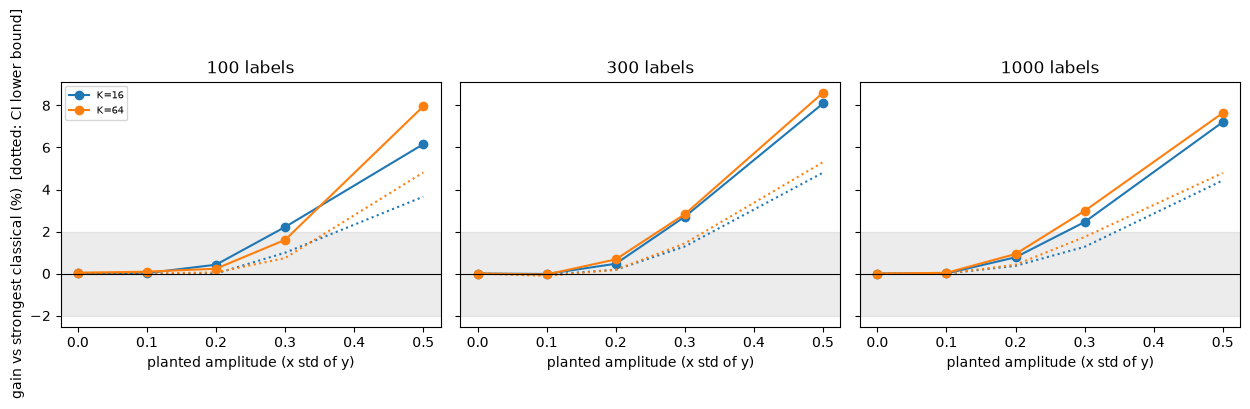

In [8]:
rows, ctabs = [], []
for amp, (d, learned) in CONF.items():
    comps = [c for c in COMPS if c in set(d.name)]; c, w = x5.claim_cells(d, learned, comps, f"wall_a{amp}", MARGIN_PCT); c["amp"] = amp; w["amp"] = amp
    ar = x5.accept_rate(d, [n for n in learned if not n.endswith("_ng")]); w["accept_rate"] = [ar.loc[a, dd] if (a in ar.index and dd in ar.columns) else np.nan for a, dd in zip(w.A, w.density)]
    ctabs.append(c); rows.append(w)
W = pd.concat(rows, ignore_index=True); W["K"] = W.A.str.extract(r"_K(\d+)")[0].astype(int); W["gated"] = ~W.A.str.endswith("_ng")
C = pd.concat(ctabs, ignore_index=True); W.to_csv(f"{V4}/confirm_claim_cells.csv", index=False); C.to_csv(f"{V4}/confirm_contrasts.csv", index=False)
print("DOSE-RESPONSE (gated arm). worst_gain_pct = mean gain vs the STRONGEST comparator; clears = CI lower bound > margin vs ALL comparators")
display(W[W.gated].pivot_table(index=["K", "density"], columns="amp", values="worst_gain_pct").round(2))
display(W[W.gated].pivot_table(index=["K", "density"], columns="amp", values="clears_margin_vs_all", aggfunc="first"))
print("accept rate of the gate:"); display(W[W.gated].pivot_table(index=["K", "density"], columns="amp", values="accept_rate").round(2))

# false-positive control: amp = 0, gated vs rk_side must be equivalent; ungated shows the cost of no gate
if 0.0 in CONF:
    fp = C[(C.amp == 0.0) & (C.B == "rk_side")][["A", "density", "mean_gain_pct", "ci_lo", "ci_hi", "verdict"]]; print("\nFALSE-POSITIVE CONTROL (amp = 0, vs rk_side):"); display(fp.round(3))
    FP_OK = bool(fp[~fp.A.str.endswith("_ng")].verdict.str.startswith("equivalent").all())
    print("gate does no harm at amp = 0:", FP_OK)
pos = W[(W.gated) & (W.amp > 0) & (W.clears_margin_vs_all)]
print("\nPOSITIVE CELLS (fresh layouts, gated prior beats EVERY comparator by > margin):", len(pos))
if len(pos):
    cross = pos.groupby(["K", "density"]).amp.min().rename("smallest_amp_that_wins").reset_index(); display(cross)
    best = pos.sort_values("worst_ci_lo", ascending=False).head(5)[["A", "density", "amp", "worst_gain_pct", "worst_ci_lo"]]; display(best.round(2))

fig, ax = plt.subplots(1, len(SD["pc_dens"]), figsize=(4.2 * len(SD["pc_dens"]), 3.4), squeeze=False, sharey=True)
for i, dd in enumerate(SD["pc_dens"]):
    for K in SD["Ks4"]:
        g = W[(W.gated) & (W.K == K) & (W.density == dd)].sort_values("amp"); ax[0, i].plot(g.amp, g.worst_gain_pct, marker="o", label=f"K={K}"); ax[0, i].plot(g.amp, g.worst_ci_lo, ls=":", color=ax[0, i].lines[-1].get_color())
    ax[0, i].axhline(0, color="k", lw=.8); ax[0, i].axhspan(-MARGIN_PCT, MARGIN_PCT, color="grey", alpha=.15); ax[0, i].set_title(f"{dd} labels"); ax[0, i].set_xlabel("planted amplitude (x std of y)")
ax[0, 0].set_ylabel("gain vs strongest classical (%)  [dotted: CI lower bound]"); ax[0, 0].legend(fontsize=7); fig.tight_layout(); fig.savefig(f"{ROOT}/figures/v4_dose_response.png", dpi=200)

## 7. What you may write

| Outcome | Wording the data allow |
|---|---|
| Stage-1 control passed, Stage 2 has positive cells, false-positive control OK | *"A pre-trained pointwise prior combined with kriging beats every classical comparator once shared side-information structure exceeds amplitude a* (K >= K*); with no shared structure the cross-validated gate returns the classical model (no harm)."* Report the dose-response figure and say plainly that this is semi-synthetic. |
| Same, and the v3 GCN arms still fail on planted maps | add: *"label-aware message passing did not recover the planted signal, a pointwise prior did: for radio maps the learnable part is the mean function, interpolation is better left to kriging."* This is consistent with your rounds 1-4 and is the strongest honest 'when do GNNs help' statement the data support. |
| Stage 1 control fails | Do not run Stage 2. Use D0 (`corr_prior_vs_f`): if ~0, `prep['X']` lacks the planted covariates; otherwise increase K or epochs and log it as v5. |
| Stage 2 shows no positive cell | Report it. The negative result is now meaningful because the same pipeline was validated on the dev layouts, but a failed confirmation is a failed confirmation. |
| amp = 0 false-positive control fails | The gate leaks: do not claim anything. |

**What still limits publishability.** This answers 'when' on a *simulator with planted structure*. A real-data positive needs a dataset where layouts share real side-information structure (Part F: DeepMIMO with building/terrain features, or Wi-Fi with an AP-position map), evaluated leave-layout-out with the same gate. Also report all arms, including the ones that lost; do not select the best amp/K after the fact.